# Step 1: why do some photos end with too few matches? (the oracle-tile test)

## What this notebook does, in simple words

Our pipeline finds a few possible places on the satellite map for each drone photo, then checks each place by matching small
landmarks between the photo and the map. The number of landmarks that agree is called **inliers**. When there are too few inliers
the pipeline says "no answer", even though many of those photos were actually close to the right place.

This notebook finds out **why** the number is low. For each photo it checks three things:

1. **The right place.** The map piece at the TRUE position of the drone (we know it for the development photos). If even this gives few matches, the problem is the photo preparation or the matcher.
2. **Places around the right one** (a little off to each side). This shows how quickly matches disappear when the guessed place is slightly wrong.
3. **The place the pipeline actually chose.** We compare it with the right place.

It also records **why a fit was thrown away** (too few pairs, RANSAC failed, a safety check on turn/size, or a safety check on how far the photo moved).

## What you will get

* A table that gives every skipped photo one cause label (explained at the end of this notebook).
* A small graph of matches against distance from the true place.
* Pictures of the photo next to the map piece, with the matched landmarks joined by lines.
* Files in `tests/Test_Iteration_3_Thresholding/results/` that you can send to me.

## Safe to run

Nothing in `src/` or in any other existing file is changed. The notebook only **reads** the pipeline. The true position is used here only to diagnose; it must never be given to the real pipeline.

## Before you start: choose the right Python (the "kernel")

A notebook runs on a Python environment called a **kernel**. It must be the one that has this project's packages (torch, kornia, lightglue ...). In this project that is `.venv-geoloc`.

**In VS Code**
1. Install the extensions **Python** and **Jupyter** (VS Code offers "Install/Enable suggested extensions" in the kernel popup).
2. Top right of the notebook: **Select Kernel** → **Python Environments** → **.venv-geoloc**.
3. If `.venv-geoloc` is not in the list, open a **terminal** (menu Terminal → New Terminal) and type these lines one by one, pressing Enter after each:

```
cd ~/Ideaforge/GeoLoc
source .venv-geoloc/bin/activate
pip install ipykernel
python -m ipykernel install --user --name geoloc --display-name "Python (.venv-geoloc)"
```

   Then close and reopen the notebook, click **Select Kernel** → **Jupyter Kernel…** and choose **Python (.venv-geoloc)**.

You will know it worked when **Block 2** below prints a Python path that contains `.venv-geoloc` and shows version numbers for torch and kornia.

## How to run it

* Click in a cell and press **Shift + Enter**. It runs that cell and moves to the next one. Wait until the `[*]` next to the cell turns into a number before you run the next cell.
* Run the cells **from the top, in order**. Do not skip a cell.
* **Red text means an error.** Copy the whole red message and send it to me.
* First time: leave `QUICK_TRY = True` in Block 1. It uses only a few photos, so you see quickly whether everything works. When it works, set `QUICK_TRY = False` and choose the menu **Kernel → Restart** (or "Restart & Run All") to do the full run.

---
## Block 1: Settings

**What it does:** finds the repo folder, and lists every choice in one place. Nothing is computed here.
Most settings are copied from `Single_Image_Run.ipynb`, because this notebook must load exactly the same photos and use exactly the same matcher as the run it diagnoses.

**What you should see:** a short summary of the settings. **You normally change only `QUICK_TRY`.**

In [1]:
# BLOCK 1 - SETTINGS. Finds the repo folder and holds every choice in one place. Nothing is computed here.
# tools used later: file paths, arrays, tables, drawing
import os, sys, math, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# --- find the repo folder: walk up from this notebook's folder until single_photo_pipeline.py is found
ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("could not find the repo folder (the one that holds single_photo_pipeline.py). Open this notebook from inside the repo.")
    ROOT = ROOT.parent
HERE = ROOT / "tests" / "Test_Iteration_3_Thresholding"
for folder in (ROOT, ROOT / "src", HERE):               # so that "import single_photo_pipeline", "import fine_matching" and "import thresholding_blocks" work
    sys.path.insert(0, str(folder))
os.chdir(ROOT)                                          # work from the repo folder so relative paths (dataset/...) resolve

# ===================== the one switch you normally change =====================
QUICK_TRY = False          # True  = a few photos only (a quick test that everything works)
                           # False = every skipped photo + 12 comparison photos (the real run)

# ===================== what to diagnose: the SAME settings as the run that made the CSV (Single_Image_Run.ipynb) =====================
RESULT_CSV = HERE / "results" / "nudt_edge_zncc_all_11890.csv"   # the saved run to diagnose
DATA = "nudt"; NUDT_SPLIT = "all"; MAP = "new"; MAP_MARGIN_M = None       # which photos and which satellite map
N_PHOTOS = 100000; SEED = 958476                              # photo sample and random seed: must stay the same, or the photos will not match the CSV
COARSE = "edge_zncc"; USE_SEMANTIC_LAYER = True; USE_SEMANTIC_DECISION = True
K_PEAKS = 50; M_FINE = 25; GAMMA = 1.0; RESCUE_INLIERS = None; RESCUE_Z = None
MATCHER = "loftr_minima"; MATCHER_CONFIDENCE = 0.3; LOFTR_COARSE_THRESHOLD = None     # "loftr_minima" or "lightglue"
MIN_INLIERS = 8; RANSAC_PIXELS = None

# ===================== how the diagnosis is done =====================
N_CONTROLS = 3 if QUICK_TRY else 12          # answered photos that earned points, probed too, for comparison
MAX_SKIPPED = 5 if QUICK_TRY else None       # None = every skipped photo
GOOD_COUNT = 8             # this many raw inliers or more counts as "a real match"
NEAR_PX = 12.0             # a candidate this close to the truth (map pixels) counts as "near" (12 px = the pipeline's own shift limit)
# map pieces tried around the truth, in MAP pixels (dx east, dy south). (0, 0) = the exact true place, it must come first.
OFFSETS_PX = [(0, 0), (8, 0), (-8, 0), (0, 8), (0, -8), (16, 0), (-16, 0), (0, 16), (0, -16), (32, 0), (-32, 0), (0, 32), (0, -32)]
SAVE_PICTURES = True       # save pictures into results/nudt/pictures
PICTURE_EVERY = 1 if QUICK_TRY else 10   # full run: a picture for every 10th skipped photo (and all controls); keeping every photo's images would fill the memory

# where the outputs (csv files, graph, pictures) are written
RESULTS = HERE / "results" / "nudt"; (RESULTS / "pictures").mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 90

print("repo folder    :", ROOT)
print("results go to  :", RESULTS)
print("run to diagnose:", RESULT_CSV.name)
print("matcher        :", MATCHER, "| QUICK_TRY =", QUICK_TRY, "(%s skipped photos, %d comparison photos)" % (MAX_SKIPPED if MAX_SKIPPED else "all", N_CONTROLS))

repo folder    : /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15
results go to  : /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_3_Thresholding/results/nudt
run to diagnose: nudt_edge_zncc_all_11890.csv
matcher        : loftr_minima | QUICK_TRY = False (all skipped photos, 12 comparison photos)


---
## Block 2: Check that everything is in place

**What it does:** shows which Python this notebook runs on, whether the needed packages are installed, whether the saved run (the CSV) and the data folders can be found, and whether a GPU is available. It also prints one line per needed data or model file: `ok` if found, `MISSING` if not.

**What you should see:**
* `Python in use` ends with something like `.venv-geoloc/bin/python`.
* A table where every package has a version number (not `MISSING`).
* `All good.` at the end.

**If it fails:** a line starting with `PROBLEM` tells you what to fix. The most common one is the wrong kernel (see "Before you start" above).

In [2]:
# BLOCK 2 - CHECKS. Which Python, which packages, which files and data. Stops with PROBLEM lines if something is missing.
from thresholding_blocks.environment_check import file_report, missing_files, package_versions, python_in_use

print("Python in use:", python_in_use())
versions = package_versions(["torch", "kornia", "lightglue", "cv2", "numpy", "pandas", "matplotlib"])
display(pd.DataFrame({"version": {name: (v if v else "MISSING") for name, v in versions.items()}}))

# ---- are all the data and model files in the right place? ("ok" = found, "MISSING" = not there)
import json
DATA_DIR = ROOT / "dataset"
OUT_DIR = HERE / "results" / "overnight"                  # where the saved fusion model is looked for (train/config.py: OUT_DIR)
needed = [
    ("official photo table",        DATA_DIR / "d1" / "images" / "metadata.csv"),
    ("new satellite map, scene A",  DATA_DIR / "Dataset_Official_2" / "268234931" / "BAND.tif"),
    ("new satellite map, scene B",  DATA_DIR / "Dataset_Official_2" / "268234921" / "BAND.tif"),
    ("LoFTR-MINIMA weights",        DATA_DIR / "NUDT" / "checkpoint" / "MINIMA" / "minima_loftr.ckpt"),
    ("DINO weights",                DATA_DIR / "NUDT" / "checkpoint" / "DINO" / "dinov2_vits14_timm.safetensors"),
    ("saved run to diagnose (CSV)", RESULT_CSV),
    ("fusion run state",            OUT_DIR / "state.json"),
]
if COARSE == "fused":                                    # the learned fusion needs its own saved model files
    try:
        best = json.load(open(OUT_DIR / "state.json"))["results"]["fusion_best"]
        needed.append(("fusion model", OUT_DIR / "models" / "fusion" / (best["tag"] + ".pt")))
        if any(name.startswith("learned") for name in best["subset"]):
            needed.append(("learned features f4", OUT_DIR / "models" / "f4.pt"))
    except Exception:
        pass                                             # state.json missing: the line above already says MISSING
file_problems = []
for found, what, path in file_report(needed):
    print("ok     " if found else "MISSING", "%-28s" % what, path)
    if not found:
        file_problems.append("%s is missing: %s" % (what, path))

problems = list(file_problems)
for name, version in versions.items():
    if version is None:
        problems.append("the package '%s' is not installed in this Python. Most likely the wrong kernel is selected: choose .venv-geoloc (see 'Before you start')." % name)
# the code files of the project itself
for path in missing_files([RESULT_CSV, ROOT / "single_photo_pipeline.py", ROOT / "src"]):
    problems.append("this file or folder is missing: %s" % path)
# can the data folders be found by the project's own search?
try:
    from train import config as repo_config
    print("official development set:", repo_config.find_dev_dir())
    print("NUDT / checkpoints      :", repo_config.find_nudt_dir())
except Exception as error:
    problems.append("could not find the data folders (%s: %s). Set the environment variable DEV_DATA_DIR / NUDT_DIR if the data is elsewhere." % (type(error).__name__, error))
if versions.get("torch"):
    import torch
    print("GPU available:", torch.cuda.is_available(), "(a GPU is strongly recommended)")

# print every problem, then stop if there is any
for line in problems:
    print("PROBLEM:", line)
assert not problems, "Fix the PROBLEM lines above, then run this cell again."
print("All good.")

Python in use: /home/palash/Ideaforge/GeoLoc/.venv-geoloc/bin/python


/home/palash/Ideaforge/GeoLoc/.venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


,version
cv2,4.8.1
kornia,0.7.1
lightglue,installed
matplotlib,3.7.5
numpy,1.23.5
pandas,1.5.3
torch,2.8.0+cu126


ok      official photo table         /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/dataset/d1/images/metadata.csv
ok      new satellite map, scene A   /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/dataset/Dataset_Official_2/268234931/BAND.tif
ok      new satellite map, scene B   /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/dataset/Dataset_Official_2/268234921/BAND.tif
ok      LoFTR-MINIMA weights         /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/dataset/NUDT/checkpoint/MINIMA/minima_loftr.ckpt
ok      DINO weights                 /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/dataset/NUDT/checkpoint/DINO/dinov2_vits14_timm.safetensors
ok      saved run to diagnose (CSV)  /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_3_Thresholding/results/nudt_edge_zncc_all_11890.csv
ok      fusion run state             /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_3_Thresho

---
## Block 3: Load the pipeline

**What it does:** builds the same pipeline as `Single_Image_Run.ipynb` (map, models, the matcher) and loads the development photos. This is the slow step; it takes about as long as the setup in `Single_Image_Run.ipynb`.

**What you should see:** lines about map levels, `setup done in ... s`, a short description of the pipeline, and the number of photos with their flight heights.

**If it fails:** copy the red error to me. A missing weights file (for example `minima_loftr.ckpt`) is the most likely cause on a new machine.

In [3]:
# BLOCK 3 - LOAD THE PIPELINE. Builds the same pipeline as Single_Image_Run.ipynb and loads the photos (slow step).
from single_photo_pipeline import SinglePhotoPipeline      # first import, as in Single_Image_Run.ipynb

pipeline = SinglePhotoPipeline(DATA, COARSE, semantic_layer=USE_SEMANTIC_LAYER, semantic_decision=USE_SEMANTIC_DECISION,
                               gamma=GAMMA, rescue_inliers=RESCUE_INLIERS, rescue_z=RESCUE_Z,
                               k_peaks=K_PEAKS, m_fine=M_FINE, matcher=MATCHER,
                               min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS, matcher_confidence=MATCHER_CONFIDENCE,
                               satellite=MAP, map_margin_m=MAP_MARGIN_M, loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD, nudt_split=NUDT_SPLIT)
start = time.time()                                    # to print how long the slow setup takes
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)
# flight heights of the loaded photos, as a sanity check
heights = np.array([item["rel_height"] for item in pipeline.test_set.items])
print("%d photos loaded, flight height %.0f to %.0f m" % (len(heights), heights.min(), heights.max()))

level 3: 0.85 m/pixel, picture 14481 x 9818, map coverage 96%
level 4: 1.20 m/pixel, picture 10240 x 6942, map coverage 96%


map store ready, took 19 s


/home/palash/Ideaforge/GeoLoc/.venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 24.1 s
data: nudt | 11890 photos available | zoom levels [3, 4]
photos: nudt | map: NUDT reference map, all split
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=25) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.30 | LoFTR coarse threshold 0.2 (default), upscale 1.0
device: cuda
11890 photos loaded, flight height 159 to 330 m


---
## Block 4: Choose the photos

**What it does:** reads the saved run (the CSV) and picks the photos to examine: every photo the pipeline **skipped** (or only the first few when `QUICK_TRY` is on), plus a few photos it **answered correctly** as a comparison.
It also checks that the photos loaded now are really the photos of the CSV (row `k` of the CSV must be photo `k` here).

**What you should see:** `The photos match the CSV.` and a small table with the number of photos per group.

**If it fails:** the message says the photos do not match. Then `DATA`, `MAP`, `N_PHOTOS` or `SEED` in Block 1 differ from the run that made the CSV. Do not continue until this is fixed, or the results would be about the wrong photos.

In [4]:
# BLOCK 4 - CHOOSE THE PHOTOS. Reads the saved CSV, checks the loaded photos are the same ones, picks skipped photos + a few answered controls.
from thresholding_blocks.photo_selection import check_matches_loaded_photos, choose_photos

# the saved run: one row per photo (answered or skipped, points)
saved_run = pd.read_csv(RESULT_CSV)
mismatch = check_matches_loaded_photos(saved_run, pipeline.test_set.items)
for line in mismatch:
    print("PROBLEM:", line)
assert not mismatch, "The photos loaded now are not the photos of the CSV. Check DATA, MAP, N_PHOTOS and SEED in Block 1."
print("The photos match the CSV.")

# (photo number, group) pairs: 'skipped' photos and 'control' photos
selected = choose_photos(saved_run, N_CONTROLS, MAX_SKIPPED)
display(pd.Series([group for _, group in selected]).value_counts().rename("photos").to_frame())
print("In the saved run: %d of %d photos were skipped." % ((~saved_run["answered"]).sum(), len(saved_run)))

The photos match the CSV.


,photos
skipped,3219
control,12


In the saved run: 3219 of 11889 photos were skipped.


---
## Block 5: Probe the photos (the main run)

**What it does:** for each chosen photo it
1. runs the normal pipeline once (unchanged), exactly as before,
2. runs the same matcher on the map piece at the **true** place, on 12 pieces slightly off to each side, on the **place the pipeline chose**, and on the first coarse guess,
3. records for each piece: how many pairs were matched, how many agree (inliers, before and after the safety checks), why a fit was rejected, and how far and how much the photo had to be moved/turned/resized to fit.

**What you should see:** a progress line every few photos, then `saved step1_probes.csv ...`. With `QUICK_TRY` this takes a few minutes after the setup; the full run takes much longer, so the progress lines tell you how far it is.

**If it fails on one photo:** that photo is listed at the end under "photos that raised an error", and the run continues with the others.

In [5]:
# BLOCK 5 - PROBE THE PHOTOS (main run). For each chosen photo: run the normal pipeline, then the matcher on the extra map pieces; save the raw tables.
from thresholding_blocks.probe_run import probe_photo

# collect one row per (photo, tile) and one row per photo
probe_rows, photo_rows, pictures_data, failures = [], [], {}, []
loop_start = time.time()
for count, (index, group) in enumerate(selected):
    try:                                                  # one bad photo must not stop the whole run
        done = probe_photo(pipeline, index, group, OFFSETS_PX, SEED)
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:150])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:150]))
        continue
    probe_rows.extend(done["probe_rows"])
    photo_rows.append(done["photo_row"])
    if group == "control" or count % PICTURE_EVERY == 0:            # keep the images of only some photos (memory)
        pictures_data[index] = dict(canvas=done["canvas"], tiles=done["tiles"], matches=done["matches"], group=group)
    if (count + 1) % 5 == 0 or count + 1 == len(selected):
        print("%d/%d photos probed, %.0f s so far" % (count + 1, len(selected), time.time() - loop_start))

# make tables and save them as CSV files in results/
probes = pd.DataFrame(probe_rows)
photos = pd.DataFrame(photo_rows)
probes.to_csv(RESULTS / "step1_probes.csv", index=False)
photos.to_csv(RESULTS / "step1_photos.csv", index=False)
print("saved step1_probes.csv (%d rows) and step1_photos.csv (%d rows) in %s" % (len(probes), len(photos), RESULTS))
if failures:
    print("photos that raised an error:"); display(pd.DataFrame(failures))

5/3231 photos probed, 4 s so far


10/3231 photos probed, 9 s so far


15/3231 photos probed, 13 s so far


20/3231 photos probed, 17 s so far


25/3231 photos probed, 21 s so far


30/3231 photos probed, 26 s so far


... (638 outputs left out)

3225/3231 photos probed, 2865 s so far


3230/3231 photos probed, 2869 s so far


3231/3231 photos probed, 2870 s so far


saved step1_probes.csv (48465 rows) and step1_photos.csv (3231 rows) in /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_3_Thresholding/results/nudt


---
## Block 6: Safety check, does our probe reproduce the pipeline?

**What it does:** our probe re-runs the matching on the place the pipeline chose. The result must be about the same as what the pipeline itself got for that place. If it is not, our probe does something different from the pipeline and the later results cannot be trusted.

**What you should see:** `OK ...` (most photos identical, small differences are normal because RANSAC uses random numbers).

**If it says `WARNING`:** stop and send me the printed lines and the table.

In [6]:
# BLOCK 6 - SAFETY CHECK. Our probe must give about the same inliers as the pipeline did for the chosen place, or later results cannot be trusted.
from thresholding_blocks.probe_tables import compare_with_pipeline

check = compare_with_pipeline(probes, photos)
identical = int((check["difference"] == 0).sum())
print("probe vs pipeline, inliers of the chosen place: %d of %d photos identical, median difference %.1f, largest difference %.0f" % (
    identical, len(check), check["difference"].median(), check["difference"].max()))
if check["difference"].median() <= 1 and check["difference"].max() <= 5:
    print("OK: the probe reproduces the pipeline.")
else:
    print("WARNING: the probe does not match the pipeline. Do not trust the next blocks; send me this output.")
    display(check.sort_values("difference", ascending=False).head(10))

probe vs pipeline, inliers of the chosen place: 3231 of 3231 photos identical, median difference 0.0, largest difference 0
OK: the probe reproduces the pipeline.


---
## Block 7: Why do some photos end with few inliers? (the main result)

**What it does:** gives each photo one **cause**. "Raw inliers" means the matches that agree **before** the pipeline's safety checks.

| cause | what it means | what we would do about it |
|---|---|---|
| `candidate_is_fine` | the chosen place already has enough raw inliers | the skip came from the answer rule, not from the matching |
| `gate_removed_a_good_fit` | enough raw inliers, but a safety check (movement or turn/size) threw the fit away | look at the check's limits and at the pose offsets |
| `weak_even_at_truth` | even the map piece at the TRUE place gives few matches | the photo preparation or the matcher is the limit |
| `candidate_too_far_from_truth` | the true place matches well but the chosen place is far from it | the guessed place is not good enough: bigger map piece or a second matching pass |
| `weak_at_candidate_near_truth` | the chosen place is near the truth and still weak | the matcher is borderline here: improve the evidence after matching |

**What you should see:** three tables: causes per group, what happened to the fit at the true place, and what happened to the fit at the chosen place. Then one row per skipped photo.

**If it fails:** copy the error to me.

In [7]:
# BLOCK 7 - CAUSES (main result). One cause label per photo: why did the chosen place end with few inliers?
from thresholding_blocks.probe_tables import cause_counts, per_photo_table

table = per_photo_table(probes, photos, GOOD_COUNT, NEAR_PX)
table.to_csv(RESULTS / "step1_per_photo.csv", index=False)
# 1) the main table: how many photos per cause
print("1) Why did the chosen place end with few inliers? (number of photos per cause)")
display(cause_counts(table))
print("2) What happened to the fit at the TRUE place? ('ok' = a good fit that passes all safety checks)")
display(table.groupby(["group", "truth_reason"]).size().unstack(fill_value=0))
print("3) What happened to the fit at the CHOSEN place?")
display(table.groupby(["group", "candidate_reason"]).size().unstack(fill_value=0))
print("4) The skipped photos one by one (sorted by matches at the true place)")
columns = ["photo", "truth_raw_inliers", "truth_pairs", "truth_reason", "candidate_raw_inliers", "candidate_pairs", "candidate_reason", "candidate_offset_px", "cause"]
display(table[table["group"] == "skipped"].sort_values("truth_raw_inliers")[columns].round(1))

1) Why did the chosen place end with few inliers? (number of photos per cause)


cause,candidate_is_fine,candidate_too_far_from_truth,gate_removed_a_good_fit,weak_at_candidate_near_truth,weak_even_at_truth
group,,,,,
control,12,0,0,0,0
skipped,0,392,94,268,2465


2) What happened to the fit at the TRUE place? ('ok' = a good fit that passes all safety checks)


truth_reason,ok,scale_angle_gate,shift_gate,too_few_pairs
group,,,,
control,12,0,0,0
skipped,1399,688,125,1007


3) What happened to the fit at the CHOSEN place?


candidate_reason,ok,scale_angle_gate,shift_gate,too_few_pairs
group,,,,
control,12,0,0,0
skipped,1294,498,171,1256


4) The skipped photos one by one (sorted by matches at the true place)


,photo,truth_raw_inliers,truth_pairs,truth_reason,candidate_raw_inliers,candidate_pairs,candidate_reason,candidate_offset_px,cause
1609,6119,0,2,too_few_pairs,0,2,too_few_pairs,0.6,weak_even_at_truth
1739,6541,0,3,too_few_pairs,2,4,scale_angle_gate,5.1,weak_even_at_truth
1736,6538,0,1,too_few_pairs,0,1,too_few_pairs,7.7,weak_even_at_truth
1734,6536,0,2,too_few_pairs,4,11,ok,4333.1,weak_even_at_truth
1731,6533,0,3,too_few_pairs,0,1,too_few_pairs,2542.8,weak_even_at_truth
...,...,...,...,...,...,...,...,...,...
171,641,56,73,scale_angle_gate,2,4,ok,5061.5,candidate_too_far_from_truth
108,447,58,66,scale_angle_gate,54,60,scale_angle_gate,14.6,gate_removed_a_good_fit
12,34,63,77,scale_angle_gate,68,83,scale_angle_gate,13.2,gate_removed_a_good_fit
3128,11170,64,85,scale_angle_gate,3,9,ok,2231.8,candidate_too_far_from_truth


---
## Block 8: How fast do the matches disappear when the map piece is off?

**What it does:** for the map pieces around the true place (0, 8, 16, 32 map pixels away) it shows the **median number of inliers** and the **share of photos with enough inliers**. If the numbers drop quickly with distance, then a slightly wrong guessed place is a main reason for low counts. It also shows how far the chosen place and the first coarse guess really were from the truth (the pipeline's own limit is 12 pixels).

**What you should see:** two small graphs (one line per group) and a table of distances.

**If it fails:** copy the error to me.

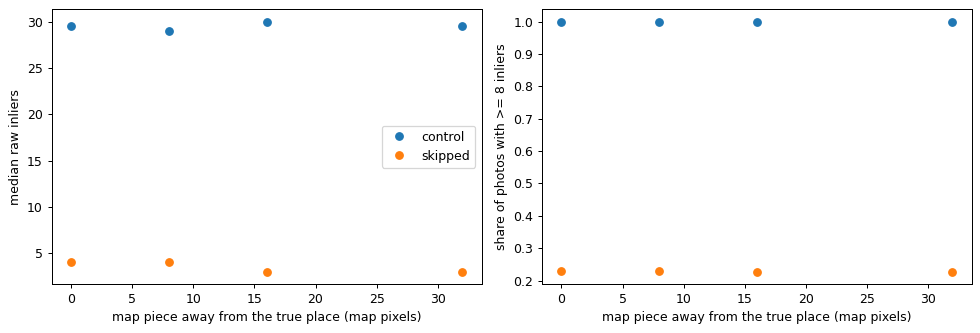

Distance from the truth, in map pixels (the pipeline accepts a shift of up to 12):


group                      control  skipped
candidate_offset_px count     12.0   3219.0
                    mean       3.7   1138.2
                    std        2.0   1643.8
                    min        1.6      0.1
                    25%        2.2      3.9
                    50%        3.3    101.1
                    75%        4.4   1945.1
                    max        8.3   9435.9
peak0_offset_px     count     12.0   3219.0
                    mean       3.7   1024.5
                    std        2.0   1587.7
                    min        1.6      0.1
                    25%        2.2      3.7
                    50%        3.3     33.9
                    75%        4.4   1713.9
                    max        8.3   8668.6

In [8]:
# BLOCK 8 - OFFSET CURVE. How fast do the matches disappear when the map piece is moved away from the true place?
from thresholding_blocks.probe_tables import offset_curve

curve = offset_curve(probes, GOOD_COUNT)
curve.to_csv(RESULTS / "step1_offset_curve.csv", index=False)
# left graph: median inliers per distance; right graph: share of photos with enough inliers
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for group, part in curve.groupby("group"):
    axes[0].plot(part["offset_px"], part["median_raw_inliers"], "o", label=group)
    axes[1].plot(part["offset_px"], part["share_at_least_good"], "o", label=group)
axes[0].set_xlabel("map piece away from the true place (map pixels)"); axes[0].set_ylabel("median raw inliers"); axes[0].legend()
axes[1].set_xlabel("map piece away from the true place (map pixels)"); axes[1].set_ylabel("share of photos with >= %d inliers" % GOOD_COUNT)
plt.tight_layout(); plt.savefig(RESULTS / "step1_offset_curve.png"); plt.show()
print("Distance from the truth, in map pixels (the pipeline accepts a shift of up to 12):")
display(photos.groupby("group")[["candidate_offset_px", "peak0_offset_px"]].describe().T.round(1))

---
## Block 9: Is the photo's centre exactly on the true position?

**What it does:** for the photos that matched well at the true place, it shows how far (east and south, in metres) the photo's centre had to move to fit the map. If the true place were perfect, this would be near zero. A steady non-zero shift means a **bias** (for example the photo centre is not exactly the GPS position, or the map is slightly offset). That would explain why many good answers stay at about 1 sigma and never reach full points.

**What you should see:** a table of statistics. Look at the **median** east and south shift.

**If it fails or prints nothing:** then no photo matched well at the true place; that is already an answer for Block 7.

In [9]:
# BLOCK 9 - TRUE-POSITION BIAS. For photos that matched well at the truth: how far did the photo centre have to move to fit the map?
from thresholding_blocks.probe_tables import truth_shift_table

shift = truth_shift_table(probes, photos, GOOD_COUNT)
shift.to_csv(RESULTS / "step1_truth_shift.csv", index=False)
if len(shift) == 0:
    print("No photo matched with >= %d raw inliers at the true place, so there is nothing to measure here." % GOOD_COUNT)
else:
    display(shift[["shift_east_m", "shift_south_m", "shift_m", "shift_sigma", "scale", "angle_deg"]].describe().round(2))
    print("median shift: east %.2f m, south %.2f m (sigma units: %.2f)" % (shift["shift_east_m"].median(), shift["shift_south_m"].median(), shift["shift_sigma"].median()))
    print("A median that is clearly not near 0 means a steady bias between the photo centre and the GPS truth (or a map offset).")

,shift_east_m,shift_south_m,shift_m,shift_sigma,scale,angle_deg
count,750.00,750.00,750.00,750.00,750.00,750.00
mean,0.15,0.23,3.83,0.48,1.02,-2.77
std,5.57,4.22,5.85,0.73,0.12,5.23
min,-114.61,-20.00,0.10,0.01,0.75,-23.92
25%,-1.56,-1.19,1.56,0.19,0.96,-4.39
50%,0.04,0.10,2.84,0.35,0.99,-1.91
75%,1.76,1.35,4.60,0.57,1.02,-0.39
max,33.96,75.99,114.91,14.33,1.56,17.10


median shift: east 0.04 m, south 0.10 m (sigma units: 0.35)
A median that is clearly not near 0 means a steady bias between the photo centre and the GPS truth (or a map offset).


---
## Block 10: Look at the pictures

**What it does:** for each photo it draws the photo (left) next to a map piece (right) and joins the matched landmarks with lines. **Green lines** are matches that agree (inliers), **red lines** are the other matches (only some of them are drawn). The top picture uses the map piece at the **true** place, the bottom one the place the pipeline **chose**. The pictures are saved in `results/pictures/`, and the first three skipped photos are shown here.

**What you should see:** if the top picture has many green lines and the bottom one few, the guessed place was the problem. If both have few green lines, the photo preparation or the matcher is the limit. Look also at whether the photo and the map piece show the same scene at all (thermal photos can look very different from the satellite picture).

**If it fails:** copy the error to me.

saved 334 pictures in /home/palash/Ideaforge/GeoLoc/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_3_Thresholding/results/nudt/pictures


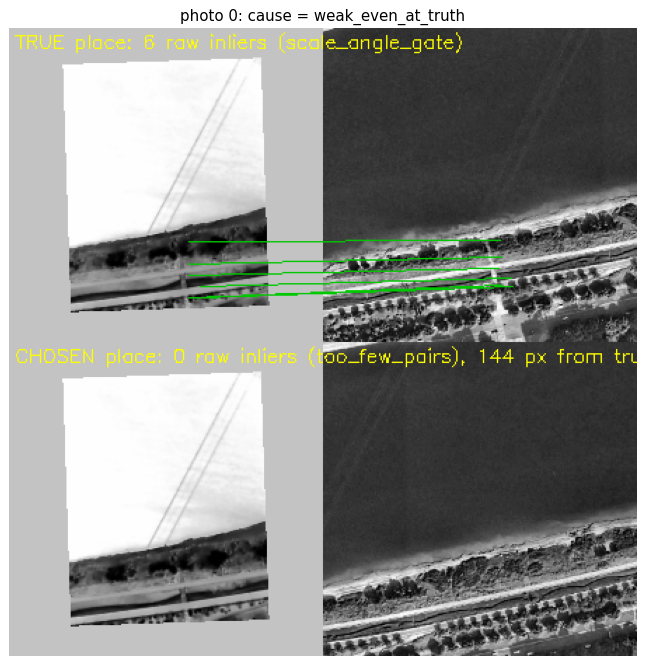

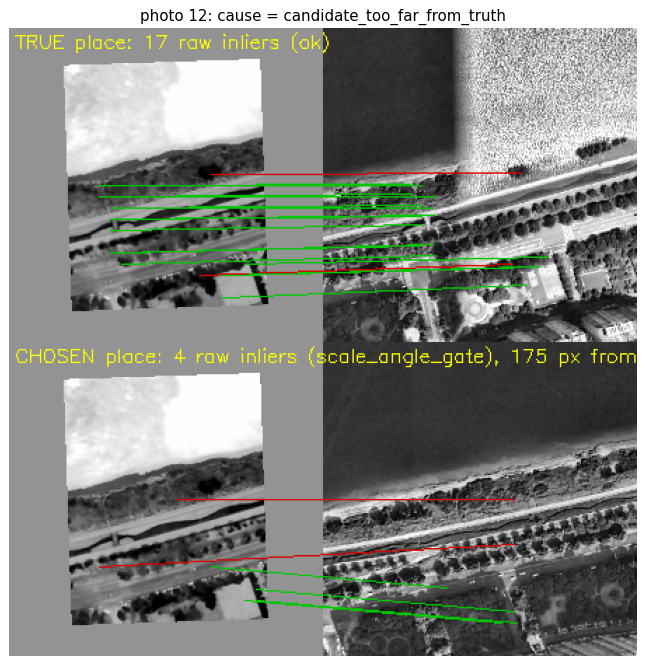

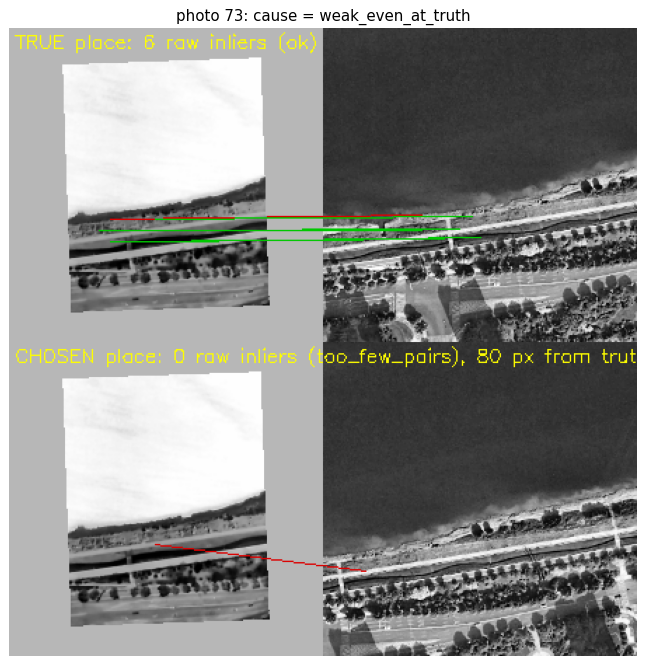

In [10]:
# BLOCK 10 - PICTURES. Photo on the left, map piece on the right, a line per match (green = agrees, red = does not).
# draws the photo and the map piece side by side with match lines
def draw_pair(canvas, tile, points_a, points_b, inlier_mask, title):
    """Photo on the left, map piece on the right, a line for each match (every inlier, one in four of the others)."""
    left = cv2.cvtColor((np.clip(canvas, 0, 1) * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    right = cv2.cvtColor((np.clip(tile, 0, 1) * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    both = np.concatenate([left, right], axis=1)
    for k in range(len(points_a)):
        if inlier_mask[k] or k % 4 == 0:
            colour = (0, 200, 0) if inlier_mask[k] else (0, 0, 220)
            cv2.line(both, (int(points_a[k, 0]), int(points_a[k, 1])), (int(points_b[k, 0]) + left.shape[1], int(points_b[k, 1])), colour, 1)
    cv2.putText(both, title, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
    return both

# builds the two-row picture of one photo: true place on top, chosen place below
def picture_of(index):
    data, row = pictures_data[index], table[table["photo"] == index].iloc[0]
    top = draw_pair(data["canvas"], data["tiles"]["truth"], *data["matches"]["truth"], "TRUE place: %d raw inliers (%s)" % (row["truth_raw_inliers"], row["truth_reason"]))
    bottom = draw_pair(data["canvas"], data["tiles"]["chosen_candidate"], *data["matches"]["chosen_candidate"],
                       "CHOSEN place: %d raw inliers (%s), %.0f px from truth" % (row["candidate_raw_inliers"], row["candidate_reason"], row["candidate_offset_px"]))
    return np.concatenate([top, bottom], axis=0), row

# save a picture per photo, then show the first three skipped photos here
if SAVE_PICTURES:
    for index in pictures_data:
        image, row = picture_of(index)
        cv2.imwrite(str(RESULTS / "pictures" / ("photo_%03d_%s_%s.png" % (index, pictures_data[index]["group"], row["cause"]))), image)
    print("saved %d pictures in %s" % (len(pictures_data), RESULTS / "pictures"))
shown = [i for i in table[table["group"] == "skipped"]["photo"] if int(i) in pictures_data][:3]
for index in shown:
    image, row = picture_of(int(index))
    plt.figure(figsize=(9, 9.2)); plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); plt.title("photo %d: cause = %s" % (index, row["cause"])); plt.axis("off"); plt.show()

---
## What to send me when it has run

1. A screenshot, or copy, of the tables from **Block 7** and the graph from **Block 8**.
2. The files in `tests/Test_Iteration_3_Thresholding/results/`: `step1_per_photo.csv`, `step1_probes.csv`, `step1_offset_curve.csv`, `step1_truth_shift.csv`, and a few pictures from `pictures/`.
3. Anything in **red**, and any line starting with `PROBLEM` or `WARNING`.

## Things to keep in mind

* The numbers come from about 100 photos, so they show directions, not exact values.
* The truth is used here only to find out why the matching is weak. The real pipeline never sees it.
* Next steps (after we read these results): improve the matches **before** the check (bigger map piece, small turn and size tries, other photo preparation), and judge the result **after** the check with more than just the inlier count. The plan is in the folder's `README.md`.